In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

print("\nFiles in ../data:")
print(os.listdir("../data"))

Current working directory:
c:\Users\shiva\OneDrive\Desktop\CarePulse\notebooks

Files in current directory:
['artifacts', 'Chest_eda.ipynb', 'Chest_model.ipynb', 'CXR_EDA.ipynb', 'CXR_findings.ipynb', 'CXR_Report.ipynb', 'Data_Preprocessing.ipynb', 'Kidney_eda.ipynb', 'kidney_model.ipynb', 'Medicine_EDA.ipynb', 'Model_training.ipynb', 'Score_model.ipynb']

Files in ../data:
['Chest Cancer', 'Chest Cancer Clean', 'cxr', 'CXR Reports', 'description.csv', 'diets.csv', 'Diseases_and_Symptoms_dataset.csv', 'Kidney Cancer', 'Kidney Cancer Clean', 'medications.csv', 'Mental_score.csv', 'precautions.csv', 'workout.csv']


In [4]:
disease_df = pd.read_csv("../data/Diseases_and_Symptoms_dataset.csv")

In [5]:
disease_df.head()

,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,...,sneezing,leg weakness,hysterical behavior,arm lump or mass,bleeding gums,pain in gums,diaper rash,hesitancy,back stiffness or tightness,low urine output
0,panic disorder,1,0,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,panic disorder,0,0,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,panic disorder,1,1,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,panic disorder,1,0,0,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,panic disorder,1,1,0,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0


## Target and Feature

In [6]:
X = disease_df.drop("diseases", axis = 1)
y = disease_df["diseases"]

In [7]:
print("Feature Matrix:", X.shape)
print("Target:", y.shape)
print("Unique Diseases:", y.nunique())

Feature Matrix: (96088, 230)
Target: (96088,)
Unique Diseases: 100


In [8]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

In [9]:
pd.DataFrame({
    "Disease": label_encoder.classes_,
    "Encoded Label": range(len(label_encoder.classes_))
}).head(10)

,Disease,Encoded Label
0,actinic keratosis,0
1,acute bronchiolitis,1
2,acute bronchitis,2
3,acute bronchospasm,3
4,acute kidney injury,4
5,acute pancreatitis,5
6,acute sinusitis,6
7,allergy,7
8,angina,8
9,anxiety,9


### Train-Test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y_encoded,test_size=0.2,
    random_state=42,stratify=y_encoded
)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

### Train Decission Tree 

In [12]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train , y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [13]:
dt_pred = dt_model.predict(X_test)

In [14]:
dt_accuracy = accuracy_score(y_test, dt_pred)
print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8561244666458528


In [15]:
print(classification_report(
    y_test,
    dt_pred,
    target_names=label_encoder.classes_
))

                                              precision    recall  f1-score   support

                           actinic keratosis       0.63      0.75      0.69       162
                         acute bronchiolitis       0.85      0.90      0.87       241
                            acute bronchitis       0.66      0.76      0.71       243
                          acute bronchospasm       0.51      0.56      0.54       162
                         acute kidney injury       0.90      0.95      0.92       162
                          acute pancreatitis       0.85      0.86      0.85       241
                             acute sinusitis       0.84      0.87      0.85       166
                                     allergy       0.94      0.96      0.95       161
                                      angina       0.86      0.96      0.91       165
                                     anxiety       0.93      0.95      0.94       240
                                appendicitis       0.

### Train Random Forest 

In [16]:
rf_model = RandomForestClassifier(n_estimators = 100 , random_state = 42)
rf_model.fit(X_train , y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [17]:
rf_pred = rf_model.predict(X_test)

In [18]:
rf_accuracy = accuracy_score(rf_pred , y_test)
print("RF accuracy:" , rf_accuracy)

RF accuracy: 0.8699656571963784


In [19]:
print(classification_report(y_test , rf_pred , 
    target_names = label_encoder.classes_))

                                              precision    recall  f1-score   support

                           actinic keratosis       0.78      0.73      0.76       162
                         acute bronchiolitis       0.92      0.89      0.90       241
                            acute bronchitis       0.74      0.72      0.73       243
                          acute bronchospasm       0.55      0.62      0.58       162
                         acute kidney injury       0.97      0.99      0.98       162
                          acute pancreatitis       0.90      0.84      0.87       241
                             acute sinusitis       0.85      0.85      0.85       166
                                     allergy       0.95      0.98      0.96       161
                                      angina       0.94      0.98      0.96       165
                                     anxiety       0.95      0.96      0.96       240
                                appendicitis       0.

### Compare RF and DT

In [20]:
comparison = pd.DataFrame({
    "Model":[
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy":[
        dt_accuracy,
        rf_accuracy
    ]
})

comparison

,Model,Accuracy
0,Decision Tree,0.856124
1,Random Forest,0.869966


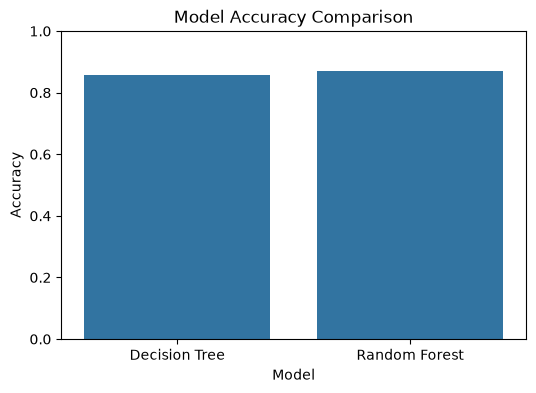

In [21]:
plt.figure(figsize=(6,4))

sns.barplot(data=comparison,x="Model",y="Accuracy")

plt.title("Model Accuracy Comparison")
plt.ylim(0,1)

plt.show()

### Confusion Matrix

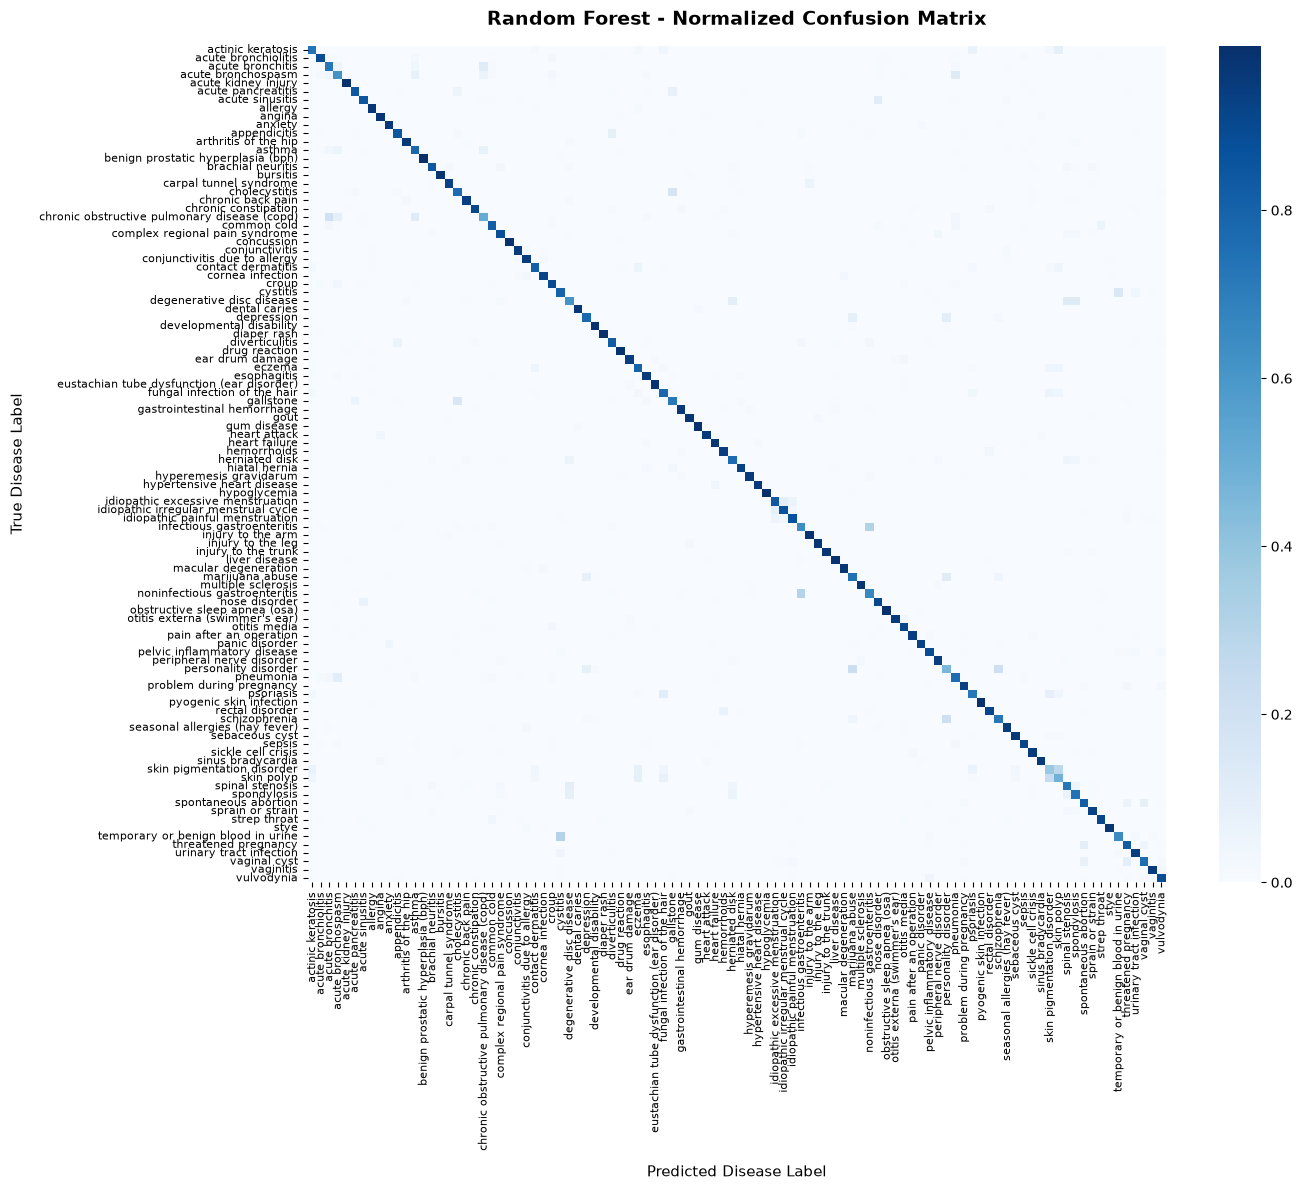

In [22]:
ARTIFACTS_DIR = "artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)
cm = confusion_matrix(y_test, rf_pred, normalize='true')

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm, 
    annot=False,            # Turn off overlapping text inside cells
    cmap="Blues", 
    cbar=True,
    xticklabels=label_encoder.classes_, 
    yticklabels=label_encoder.classes_
)

plt.title("Random Forest - Normalized Confusion Matrix", fontsize=14, weight='bold', pad=15)
plt.xlabel("Predicted Disease Label", fontsize=11, labelpad=10)
plt.ylabel("True Disease Label", fontsize=11, labelpad=10)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
save_path = os.path.join(ARTIFACTS_DIR, "confusion_matrix.png")
plt.savefig(save_path, dpi=300)
plt.show()

### Feature - Importance

In [23]:
feature_importance = pd.DataFrame({
    "Symptom": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Symptom,Importance
41,headache,0.020454
40,vomiting,0.016939
86,burning abdominal pain,0.012909
77,back pain,0.012851
42,nausea,0.012169
4,sharp chest pain,0.011708
15,cough,0.011453
133,fever,0.010924
38,sharp abdominal pain,0.010615
82,pelvic pain,0.010413


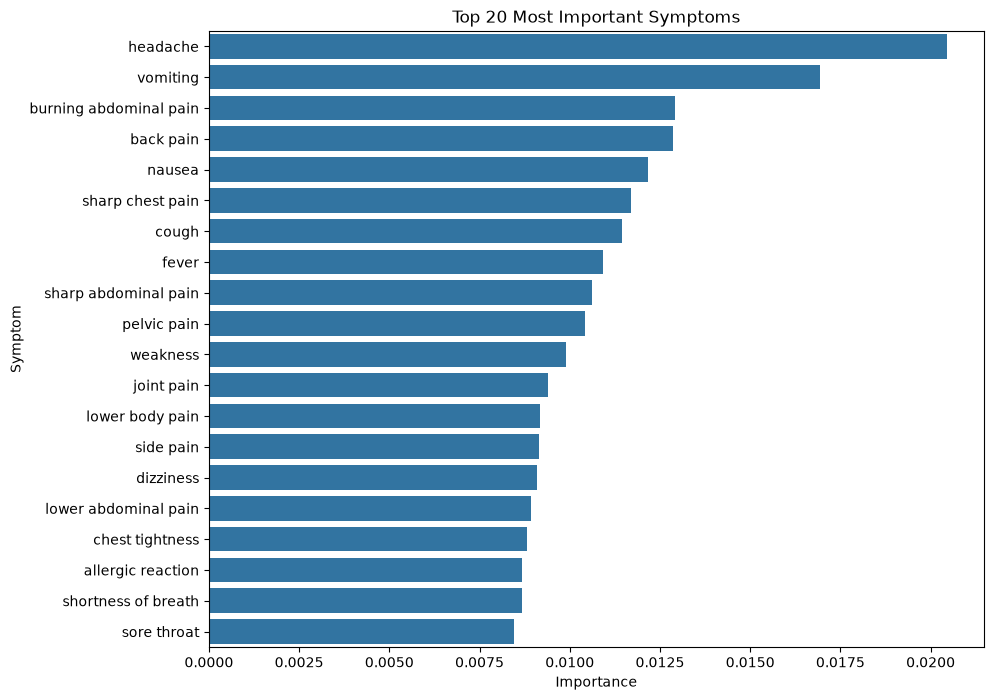

In [24]:
plt.figure(figsize=(10,8))

sns.barplot(
    data=feature_importance.head(20),
    x="Importance",
    y="Symptom"
)

plt.title("Top 20 Most Important Symptoms")

plt.show()

### Pickle dump file

In [25]:
import os
import pickle

os.makedirs("../artifacts", exist_ok=True)

with open("../artifacts/disease_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("../artifacts/label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

with open("../artifacts/symptom_columns.pkl", "wb") as f:
    pickle.dump(X.columns.tolist(), f)

In [26]:
with open("../artifacts/disease_model.pkl","rb") as f:
    model = pickle.load(f)

with open("../artifacts/label_encoder.pkl","rb") as f:
    encoder = pickle.load(f)

with open("../artifacts/symptom_columns.pkl","rb") as f:
    symptom_columns = pickle.load(f)

print(type(model))
print(type(encoder))
print(type(symptom_columns))
print("Total Symptoms:",len(symptom_columns))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
<class 'sklearn.preprocessing._label.LabelEncoder'>
<class 'list'>
Total Symptoms: 230


In [27]:
import os

print(os.path.exists("../artifacts/disease_model.pkl"))
print(os.path.exists("../artifacts/label_encoder.pkl"))
print(os.path.exists("../artifacts/symptom_columns.pkl"))

True
True
True


In [28]:
print("Model expects:", model.n_features_in_)
print("Symptoms available:", len(symptom_columns))

Model expects: 230
Symptoms available: 230
